# Smart Traffic Intelligence System
## Phase 2: Data Cleaning and Feature Engineering

### Objectives
1. Load the original accident dataset.
2. Identify and handle missing values.
3. Check duplicate collision records.
4. Validate geographical coordinates.
5. Clean date and time information.
6. Create useful time-based features.
7. Create accident severity categories.
8. Save the cleaned dataset.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 3.1.0
NumPy version: 2.5.4


In [2]:
from pathlib import Path

# Get the project directory
PROJECT_DIR = Path.cwd()

# If notebook is running from notebooks folder
if not (PROJECT_DIR / "dataset").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Original dataset location
RAW_DATA_PATH = (
    PROJECT_DIR / "dataset" / "raw" / "traffic_accidents.csv"
)

# Processed dataset folder
PROCESSED_DIR = (
    PROJECT_DIR / "dataset" / "processed"
)

# Create processed folder if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Final cleaned dataset location
OUTPUT_PATH = PROCESSED_DIR / "cleaned_accidents.csv"

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("RAW DATASET PATH:", RAW_DATA_PATH)
print("PROCESSED DIRECTORY:", PROCESSED_DIR)
print("OUTPUT FILE:", OUTPUT_PATH)

print("\nOriginal dataset exists:", RAW_DATA_PATH.exists())

PROJECT DIRECTORY: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project
RAW DATASET PATH: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\dataset\raw\traffic_accidents.csv
PROCESSED DIRECTORY: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\dataset\processed
OUTPUT FILE: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\dataset\processed\cleaned_accidents.csv

Original dataset exists: True


In [3]:
# Load the original accident dataset

RAW_DATA_PATH = PROJECT_DIR / "dataset" / "raw" / "traffic_accidents.csv"

df = pd.read_csv(
    RAW_DATA_PATH,
    low_memory=False
)

# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

print("DATASET LOADED SUCCESSFULLY")
print("-" * 50)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

DATASET LOADED SUCCESSFULLY
--------------------------------------------------
Dataset Shape: (2301644, 29)

First 5 Records:


,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,cross_street_name,off_street_name,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,contributing_factor_vehicle_1,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code_1,vehicle_type_code_2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
0,10/27/2026,15:48,MANHATTAN,10013.0,40.720448,-74.005590,"(40.720448, -74.00559)",NaN,260 W BROADWAY,NaN,0.0,0.0,0,0,0,0,0,0,Does Not Apply,Does Not Apply,NaN,NaN,NaN,73fa239b448001d1b74e285a42d70488,4 dr sedan,Taxi,NaN,NaN,NaN
1,10/27/2026,23:54,BROOKLYN,11219.0,40.641815,-73.995810,"(40.641815, -73.99581)",10 AVE,NaN,44 ST,0.0,0.0,0,0,0,0,0,0,Does Not Apply,Does Not Apply,NaN,NaN,NaN,1ca9703d3d16fae179d917b36065331a,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN
2,10/27/2026,12:35,QUEENS,11433.0,40.704185,-73.785980,"(40.704185, -73.78598)",172 ST,NaN,LIBERTY AVE,2.0,0.0,0,0,0,0,2,0,Driver Inattention/Distraction,Driver Inattention/Distraction,NaN,NaN,NaN,005e53cae38738ee5bbedf0da83662f1,4 dr sedan,4 dr sedan,NaN,NaN,NaN
3,10/27/2026,07:35,BRONX,NaN,NaN,NaN,NaN,W 179TH,NaN,MAJOR DEEGAN EXPY,0.0,0.0,0,0,0,0,0,0,Does Not Apply,Does Not Apply,NaN,NaN,NaN,ca38ea795663bff25cf2728441997fbe,4 dr sedan,NaN,NaN,NaN,NaN
4,10/27/2026,15:53,MANHATTAN,10034.0,40.860910,-73.921524,"(40.86091, -73.921524)",ACADEMY ST,NaN,10 AVE,0.0,0.0,0,0,0,0,0,0,Does Not Apply,Oversized Vehicle,NaN,NaN,NaN,d803d9ca816ccde76301f0bad3b8b5e5,Bus (Omnibus),Stake Truck,NaN,NaN,NaN



Column Names:
['crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'location', 'on_street_name', 'cross_street_name', 'off_street_name', 'number_of_persons_injured', 'number_of_persons_killed', 'number_of_pedestrians_injured', 'number_of_pedestrians_killed', 'number_of_cyclist_injured', 'number_of_cyclist_killed', 'number_of_motorist_injured', 'number_of_motorist_killed', 'contributing_factor_vehicle_1', 'contributing_factor_vehicle_2', 'contributing_factor_vehicle_3', 'contributing_factor_vehicle_4', 'contributing_factor_vehicle_5', 'collision_id', 'vehicle_type_code_1', 'vehicle_type_code_2', 'vehicle_type_code_3', 'vehicle_type_code_4', 'vehicle_type_code_5']


In [4]:
# MISSING VALUE ANALYSIS

missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": missing_count.values,
    "Missing_Percentage": missing_percentage.values
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("MISSING VALUE ANALYSIS")
print("=" * 60)

display(missing_report)

print("\nTotal missing values:", df.isnull().sum().sum())

print(
    "Columns containing missing values:",
    df.isnull().any().sum()
)

MISSING VALUE ANALYSIS


,Column,Missing_Count,Missing_Percentage
28,vehicle_type_code_5,2291475,99.56
22,contributing_factor_vehicle_5,2291136,99.54
27,vehicle_type_code_4,2264762,98.40
21,contributing_factor_vehicle_4,2263318,98.33
26,vehicle_type_code_3,2141423,93.04
20,contributing_factor_vehicle_3,2134534,92.74
8,cross_street_name,1884385,81.87
9,off_street_name,885473,38.47
3,zip_code,699226,30.38
2,borough,674813,29.32



Total missing values: 19636061
Columns containing missing values: 20


In [5]:
# Display complete missing-value report

print("COMPLETE MISSING VALUE REPORT")
print("=" * 75)

print(
    missing_report.to_string(index=False)
)

print("\n" + "=" * 75)
print("Total dataset records:", len(df))
print("Total dataset columns:", len(df.columns))

COMPLETE MISSING VALUE REPORT
                       Column  Missing_Count  Missing_Percentage
          vehicle_type_code_5        2291475               99.56
contributing_factor_vehicle_5        2291136               99.54
          vehicle_type_code_4        2264762               98.40
contributing_factor_vehicle_4        2263318               98.33
          vehicle_type_code_3        2141423               93.04
contributing_factor_vehicle_3        2134534               92.74
            cross_street_name        1884385               81.87
              off_street_name         885473               38.47
                     zip_code         699226               30.38
                      borough         674813               29.32
               on_street_name         509678               22.14
          vehicle_type_code_2         474109               20.60
contributing_factor_vehicle_2         373602               16.23
                     location         240734               1

In [6]:
# DUPLICATE COLLISION ID ANALYSIS

print("DUPLICATE RECORD ANALYSIS")
print("=" * 60)

print("Total duplicate rows:", df.duplicated().sum())

if "collision_id" in df.columns:

    print(
        "Missing collision IDs:",
        df["collision_id"].isna().sum()
    )

    print(
        "Duplicate collision IDs:",
        df["collision_id"].duplicated().sum()
    )

    duplicate_id_rows = df[
        df["collision_id"].duplicated(keep=False)
    ]

    print(
        "Records involved in duplicate IDs:",
        len(duplicate_id_rows)
    )

else:
    print("collision_id column not found.")

DUPLICATE RECORD ANALYSIS
Total duplicate rows: 0
Missing collision IDs: 0
Duplicate collision IDs: 0
Records involved in duplicate IDs: 0


In [7]:
# STEP 9: GEOGRAPHICAL COORDINATE VALIDATION

# Convert latitude and longitude into numeric values
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

# Check valid NYC geographical coordinates
valid_coordinates = (
    df["latitude"].between(40.4, 41.0)
    & df["longitude"].between(-74.3, -73.6)
)

# Create a flag instead of deleting records
df["valid_coordinates"] = valid_coordinates

# Display coordinate validation results
print("GEOGRAPHICAL COORDINATE VALIDATION")
print("=" * 50)

print("Total accident records:", len(df))
print("Valid coordinate records:", df["valid_coordinates"].sum())
print("Invalid or missing coordinates:", (~df["valid_coordinates"]).sum())

print("\nCoordinate Validation Status:")
display(df[[
    "latitude",
    "longitude",
    "valid_coordinates"
]].head(10))

GEOGRAPHICAL COORDINATE VALIDATION
Total accident records: 2301644
Valid coordinate records: 2052348
Invalid or missing coordinates: 249296

Coordinate Validation Status:


,latitude,longitude,valid_coordinates
0,40.720448,-74.005590,True
1,40.641815,-73.995810,True
2,40.704185,-73.785980,True
3,NaN,NaN,False
4,40.860910,-73.921524,True
5,40.637577,-73.925920,True
6,40.640160,-73.995290,True
7,40.822070,-73.949920,True
8,40.595880,-73.938900,True
9,40.717678,-73.817120,True


In [8]:
# STEP 10: HANDLE MISSING VALUES

# Create a copy of the original dataset
clean_df = df.copy()

# Fill missing borough values
if "borough" in clean_df.columns:
    clean_df["borough"] = clean_df["borough"].fillna("Unknown")

# Fill missing street information
street_columns = [
    "on_street_name",
    "off_street_name",
    "cross_street_name"
]

for column in street_columns:
    if column in clean_df.columns:
        clean_df[column] = clean_df[column].fillna("Not Available")

# Fill missing categorical vehicle and contributing factor values
categorical_columns = [
    column for column in clean_df.columns
    if column.startswith("vehicle_type_code_")
    or column.startswith("contributing_factor_vehicle_")
]

for column in categorical_columns:
    clean_df[column] = clean_df[column].fillna("Unspecified")

# Fill missing injury and fatality counts with zero
count_columns = [
    column for column in clean_df.columns
    if column.startswith("number_of_")
]

for column in count_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column], errors="coerce"
    ).fillna(0)

# Display missing-value report after handling
remaining_missing = clean_df.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

print("MISSING VALUE HANDLING REPORT")
print("=" * 50)
print("Total records:", len(clean_df))
print("Total missing values remaining:", clean_df.isnull().sum().sum())

print("\nColumns still containing missing values:")
display(remaining_missing.to_frame(name="Missing_Count"))

MISSING VALUE HANDLING REPORT
Total records: 2301644
Total missing values remaining: 1421428

Columns still containing missing values:


,Missing_Count
zip_code,699226
latitude,240734
longitude,240734
location,240734


In [9]:
# STEP 11: CREATE ACCIDENT SEVERITY CATEGORIES

# Ensure injury and fatality columns are numeric
clean_df["number_of_persons_injured"] = pd.to_numeric(
    clean_df["number_of_persons_injured"],
    errors="coerce"
).fillna(0)

clean_df["number_of_persons_killed"] = pd.to_numeric(
    clean_df["number_of_persons_killed"],
    errors="coerce"
).fillna(0)

# Create severity categories
conditions = [
    clean_df["number_of_persons_killed"] > 0,
    clean_df["number_of_persons_injured"] > 0
]

categories = [
    "Fatal",
    "Injury"
]

clean_df["accident_severity"] = np.select(
    conditions,
    categories,
    default="Property Damage Only"
)

# Display severity distribution
severity_counts = clean_df["accident_severity"].value_counts()

print("ACCIDENT SEVERITY DISTRIBUTION")
print("=" * 50)

display(severity_counts.to_frame(name="Accident_Count"))

print("\nSeverity percentages:")
display(
    (clean_df["accident_severity"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame(name="Percentage")
)

ACCIDENT SEVERITY DISTRIBUTION


,Accident_Count
accident_severity,
Property Damage Only,1725037
Injury,573026
Fatal,3581



Severity percentages:


,Percentage
accident_severity,
Property Damage Only,74.95
Injury,24.90
Fatal,0.16


In [10]:
# STEP 12: FEATURE ENGINEERING

# Convert crash date and time
clean_df["crash_date"] = pd.to_datetime(
    clean_df["crash_date"], errors="coerce"
)

clean_df["crash_time_parsed"] = pd.to_datetime(
    clean_df["crash_time"].astype(str),
    format="%H:%M",
    errors="coerce"
)

# Extract time-based features
clean_df["crash_hour"] = clean_df["crash_time_parsed"].dt.hour

clean_df["day_of_week"] = clean_df["crash_date"].dt.day_name()

clean_df["month"] = clean_df["crash_date"].dt.month

clean_df["year"] = clean_df["crash_date"].dt.year

clean_df["is_weekend"] = (
    clean_df["crash_date"].dt.dayofweek >= 5
).astype("boolean")

# Create time-period categories
def classify_time(hour):
    if pd.isna(hour):
        return "Unknown"
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

clean_df["time_period"] = clean_df["crash_hour"].apply(classify_time)

# Create total affected persons
clean_df["total_persons_affected"] = (
    clean_df["number_of_persons_injured"]
    + clean_df["number_of_persons_killed"]
)

# Display engineered features
print("FEATURE ENGINEERING COMPLETED")
print("=" * 50)

display(clean_df[[
    "crash_date",
    "crash_time",
    "crash_hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend",
    "time_period",
    "total_persons_affected",
    "accident_severity"
]].head(10))

FEATURE ENGINEERING COMPLETED


,crash_date,crash_time,crash_hour,day_of_week,month,year,is_weekend,time_period,total_persons_affected,accident_severity
0,2026-10-27,15:48,15,Tuesday,10,2026,False,Afternoon,0.0,Property Damage Only
1,2026-10-27,23:54,23,Tuesday,10,2026,False,Night,0.0,Property Damage Only
2,2026-10-27,12:35,12,Tuesday,10,2026,False,Afternoon,2.0,Injury
3,2026-10-27,07:35,7,Tuesday,10,2026,False,Morning,0.0,Property Damage Only
4,2026-10-27,15:53,15,Tuesday,10,2026,False,Afternoon,0.0,Property Damage Only
5,2026-10-27,18:20,18,Tuesday,10,2026,False,Evening,2.0,Injury
6,2026-10-27,11:32,11,Tuesday,10,2026,False,Morning,0.0,Property Damage Only
7,2026-10-27,01:34,1,Tuesday,10,2026,False,Night,1.0,Injury
8,2026-10-27,15:28,15,Tuesday,10,2026,False,Afternoon,0.0,Property Damage Only
9,2026-10-27,15:30,15,Tuesday,10,2026,False,Afternoon,1.0,Injury


In [11]:
from pathlib import Path

# Identify project directory
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "dataset").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Output directory
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Output file
OUTPUT_PATH = PROCESSED_DIR / "cleaned_accidents.csv"

# Verify cleaned dataframe exists
if "clean_df" not in globals():
    raise NameError(
        "clean_df not found. Run all previous cleaning cells first."
    )

# Save cleaned dataset
clean_df.to_csv(OUTPUT_PATH, index=False)

print("CLEANED DATASET SAVED SUCCESSFULLY!")
print("Records:", len(clean_df))
print("Columns:", len(clean_df.columns))
print("Saved location:", OUTPUT_PATH)
print("File exists:", OUTPUT_PATH.exists())
print("File size (MB):", round(OUTPUT_PATH.stat().st_size / (1024 * 1024), 2))

CLEANED DATASET SAVED SUCCESSFULLY!
Records: 2301644
Columns: 39
Saved location: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\dataset\processed\cleaned_accidents.csv
File exists: True
File size (MB): 865.81


DATA QUALITY ANALYSIS

Dataset loaded successfully!
Rows: 2301644
Columns: 29

1. DATASET OVERVIEW


,crash date,crash time,borough,zip code,latitude,longitude,location,on street name,cross street name,off street name,...,contributing factor vehicle 2,contributing factor vehicle 3,contributing factor vehicle 4,contributing factor vehicle 5,collision_id,vehicle type code 1,vehicle type code 2,vehicle type code 3,vehicle type code 4,vehicle type code 5
0,10/27/2026,15:48,MANHATTAN,10013.0,40.720448,-74.005590,"(40.720448, -74.00559)",NaN,260 W BROADWAY,NaN,...,Does Not Apply,NaN,NaN,NaN,73fa239b448001d1b74e285a42d70488,4 dr sedan,Taxi,NaN,NaN,NaN
1,10/27/2026,23:54,BROOKLYN,11219.0,40.641815,-73.995810,"(40.641815, -73.99581)",10 AVE,NaN,44 ST,...,Does Not Apply,NaN,NaN,NaN,1ca9703d3d16fae179d917b36065331a,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN
2,10/27/2026,12:35,QUEENS,11433.0,40.704185,-73.785980,"(40.704185, -73.78598)",172 ST,NaN,LIBERTY AVE,...,Driver Inattention/Distraction,NaN,NaN,NaN,005e53cae38738ee5bbedf0da83662f1,4 dr sedan,4 dr sedan,NaN,NaN,NaN
3,10/27/2026,07:35,BRONX,NaN,NaN,NaN,NaN,W 179TH,NaN,MAJOR DEEGAN EXPY,...,Does Not Apply,NaN,NaN,NaN,ca38ea795663bff25cf2728441997fbe,4 dr sedan,NaN,NaN,NaN,NaN
4,10/27/2026,15:53,MANHATTAN,10034.0,40.860910,-73.921524,"(40.86091, -73.921524)",ACADEMY ST,NaN,10 AVE,...,Oversized Vehicle,NaN,NaN,NaN,d803d9ca816ccde76301f0bad3b8b5e5,Bus (Omnibus),Stake Truck,NaN,NaN,NaN



Dataset Shape: (2301644, 29)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2301644 entries, 0 to 2301643
Data columns (total 29 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   crash date                     str    
 1   crash time                     str    
 2   borough                        str    
 3   zip code                       float64
 4   latitude                       float64
 5   longitude                      float64
 6   location                       str    
 7   on street name                 str    
 8   cross street name              str    
 9   off street name                str    
 10  number of persons injured      float64
 11  number of persons killed       float64
 12  number of pedestrians injured  int64  
 13  number of pedestrians killed   int64  
 14  number of cyclist injured      int64  
 15  number of cyclist killed       int64  
 16  number of motorist injured     int64  
 17  numbe

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
crash date,2301644,5232,01/21/2014,1161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash time,2301644,1440,16:00,30448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borough,1626831,5,BROOKLYN,521523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip code,1602418.0,NaN,NaN,NaN,10845.119111,552.148498,10000.0,10309.0,11207.0,11237.0,12345.0
latitude,2060910.0,NaN,NaN,NaN,40.557617,2.59783,0.0,40.66718,40.720076,40.769657,43.344444
longitude,2060910.0,NaN,NaN,NaN,-73.624485,4.803534,-201.35999,-73.974444,-73.926468,-73.8663,0.0
location,2060910,358416,"(0.0, 0.0)",8413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
on street name,1791966,17825,BROADWAY,21585,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cross street name,417259,252443,772 EDGEWATER ROAD,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
off street name,1416171,19094,BROADWAY,17503,NaN,NaN,NaN,NaN,NaN,NaN,NaN



2. MISSING VALUE ANALYSIS


,Column,Missing_Count,Missing_Percentage
28,vehicle type code 5,2291475,99.56
22,contributing factor vehicle 5,2291136,99.54
27,vehicle type code 4,2264762,98.40
21,contributing factor vehicle 4,2263318,98.33
26,vehicle type code 3,2141423,93.04
20,contributing factor vehicle 3,2134534,92.74
8,cross street name,1884385,81.87
9,off street name,885473,38.47
3,zip code,699226,30.38
2,borough,674813,29.32


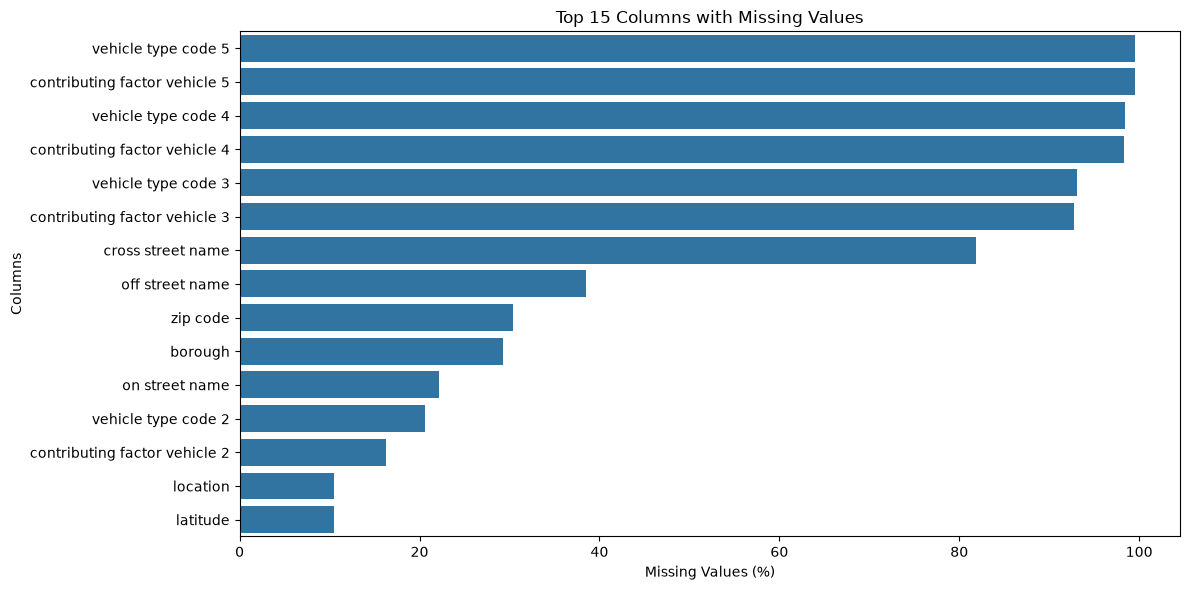


3. DUPLICATE RECORD ANALYSIS
Total Duplicate Records: 0
Duplicate Percentage: 0.0 %

4. DATA TYPE ANALYSIS


,Column,Data_Type
0,crash date,str
1,crash time,str
2,borough,str
3,zip code,float64
4,latitude,float64
5,longitude,float64
6,location,str
7,on street name,str
8,cross street name,str
9,off street name,str



5. DATE VALIDATION
crash_date column not found.

6. TIME VALIDATION
crash_time column not found.

7. GEOGRAPHICAL VALIDATION
Missing/Non-numeric Coordinates: 240734
Coordinates Outside Approximate NYC Bounds: 8545

8. INJURY AND FATALITY VALIDATION
number_of_persons_injured not found.
number_of_persons_killed not found.

9. CATEGORICAL DATA ANALYSIS

Column: borough
Unique Values: 5


,Count
borough,
NaN,674813
BROOKLYN,521523
QUEENS,437708
MANHATTAN,356888
BRONX,242904
STATEN ISLAND,67808


contributing_factor_vehicle_1 not found.
vehicle_type_code_1 not found.

10. NUMERIC DATA ANALYSIS


,count,mean,std,min,25%,50%,75%,max
zip code,1602418.0,10845.119111,552.148498,10000.00000,10309.000000,11207.000000,11237.000000,12345.000000
latitude,2060910.0,40.557617,2.597830,0.00000,40.667180,40.720076,40.769657,43.344444
longitude,2060910.0,-73.624485,4.803534,-201.35999,-73.974444,-73.926468,-73.866300,0.000000
number of persons injured,2301626.0,0.337578,0.722127,0.00000,0.000000,0.000000,0.000000,43.000000
number of persons killed,2301613.0,0.001624,0.042549,0.00000,0.000000,0.000000,0.000000,8.000000
number of pedestrians injured,2301644.0,0.061312,0.253340,0.00000,0.000000,0.000000,0.000000,27.000000
number of pedestrians killed,2301644.0,0.000801,0.028924,0.00000,0.000000,0.000000,0.000000,6.000000
number of cyclist injured,2301644.0,0.029806,0.172358,0.00000,0.000000,0.000000,0.000000,4.000000
number of cyclist killed,2301644.0,0.000119,0.010950,0.00000,0.000000,0.000000,0.000000,2.000000
number of motorist injured,2301644.0,0.239822,0.682765,0.00000,0.000000,0.000000,0.000000,43.000000



11. DATA QUALITY SUMMARY


C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_23684\3249614583.py:307: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=["object", "category"]).columns


,Metric,Value
0,Total Records,2301644
1,Total Columns,29
2,Total Missing Values,19636061
3,Duplicate Records,0
4,Numeric Columns,11
5,Categorical Columns,18



12. REPORT GENERATION
Reports saved successfully in: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\reports

Generated Reports:
1. missing_values_report.csv
2. data_types_report.csv
3. data_quality_summary.csv

DATA QUALITY ANALYSIS COMPLETED SUCCESSFULLY!


In [1]:

# ============================================================
# SMART TRAFFIC & ACCIDENT INTELLIGENCE SYSTEM
# PHASE 2: DATA QUALITY ANALYSIS
# Dataset: NYC Motor Vehicle Collisions
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. LOAD DATASET
# ============================================================

PROJECT_ROOT = Path.cwd()

# Support running from either project root or notebooks folder
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "dataset" / "raw" / "traffic_accidents.csv"

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)

df.columns = df.columns.str.strip().str.lower()

print("=" * 60)
print("DATA QUALITY ANALYSIS")
print("=" * 60)

print("\nDataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# ============================================================
# 2. DATASET OVERVIEW
# ============================================================

print("\n1. DATASET OVERVIEW")

display(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

# ============================================================
# 3. MISSING VALUE ANALYSIS
# ============================================================

print("\n2. MISSING VALUE ANALYSIS")

missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report)

missing_report.to_csv(
    REPORT_PATH / "missing_values_report.csv",
    index=False
)

# Missing value visualization
missing_data = missing_report[
    missing_report["Missing_Count"] > 0
]

if not missing_data.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=missing_data.head(15),
        x="Missing_Percentage",
        y="Column"
    )

    plt.title("Top 15 Columns with Missing Values")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Columns")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

# ============================================================
# 4. DUPLICATE RECORD ANALYSIS
# ============================================================

print("\n3. DUPLICATE RECORD ANALYSIS")

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

duplicate_percentage = (
    duplicate_count / len(df) * 100
    if len(df) > 0 else 0
)

print("Duplicate Percentage:", round(duplicate_percentage, 2), "%")

# ============================================================
# 5. DATA TYPE ANALYSIS
# ============================================================

print("\n4. DATA TYPE ANALYSIS")

dtype_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

display(dtype_report)

dtype_report.to_csv(
    REPORT_PATH / "data_types_report.csv",
    index=False
)

# ============================================================
# 6. DATE VALIDATION
# ============================================================

print("\n5. DATE VALIDATION")

if "crash_date" in df.columns:

    parsed_dates = pd.to_datetime(
        df["crash_date"],
        errors="coerce"
    )

    invalid_dates = (
        df["crash_date"].notna() & parsed_dates.isna()
    ).sum()

    missing_dates = df["crash_date"].isna().sum()

    print("Invalid Dates:", invalid_dates)
    print("Missing Dates:", missing_dates)

else:
    print("crash_date column not found.")

# ============================================================
# 7. TIME VALIDATION
# ============================================================

print("\n6. TIME VALIDATION")

if "crash_time" in df.columns:

    parsed_times = pd.to_datetime(
        df["crash_time"].astype("string").str.strip(),
        format="%H:%M",
        errors="coerce"
    )

    invalid_times = (
        df["crash_time"].notna() & parsed_times.isna()
    ).sum()

    print("Invalid Time Values:", invalid_times)
    print("Missing Time Values:", df["crash_time"].isna().sum())

else:
    print("crash_time column not found.")

# ============================================================
# 8. GEOGRAPHICAL VALIDATION
# ============================================================

print("\n7. GEOGRAPHICAL VALIDATION")

if {"latitude", "longitude"}.issubset(df.columns):

    latitude = pd.to_numeric(
        df["latitude"], errors="coerce"
    )

    longitude = pd.to_numeric(
        df["longitude"], errors="coerce"
    )

    missing_coordinates = (
        latitude.isna() | longitude.isna()
    ).sum()

    invalid_coordinates = (
        latitude.notna()
        & longitude.notna()
        & (
            ~latitude.between(40, 42)
            | ~longitude.between(-75, -73)
        )
    ).sum()

    print("Missing/Non-numeric Coordinates:", missing_coordinates)

    print(
        "Coordinates Outside Approximate NYC Bounds:",
        invalid_coordinates
    )

else:
    print("Latitude or longitude column not found.")

# ============================================================
# 9. INJURY AND FATALITY VALIDATION
# ============================================================

print("\n8. INJURY AND FATALITY VALIDATION")

count_columns = [
    "number_of_persons_injured",
    "number_of_persons_killed"
]

for column in count_columns:

    if column in df.columns:

        values = pd.to_numeric(
            df[column], errors="coerce"
        )

        negative_count = (values < 0).sum()

        print(f"{column}:")
        print("Negative Values:", negative_count)
        print("Missing Values:", values.isna().sum())

    else:
        print(column, "not found.")

# ============================================================
# 10. CATEGORICAL DATA ANALYSIS
# ============================================================

print("\n9. CATEGORICAL DATA ANALYSIS")

categorical_columns = [
    "borough",
    "contributing_factor_vehicle_1",
    "vehicle_type_code_1"
]

for column in categorical_columns:

    if column in df.columns:

        print("\nColumn:", column)
        print("Unique Values:", df[column].nunique())

        display(
            df[column]
            .value_counts(dropna=False)
            .head(10)
            .to_frame("Count")
        )

    else:
        print(column, "not found.")

# ============================================================
# 11. NUMERIC DATA ANALYSIS
# ============================================================

print("\n10. NUMERIC DATA ANALYSIS")

numeric_df = df.select_dtypes(include=np.number)

display(numeric_df.describe().T)

# ============================================================
# 12. DATA QUALITY SUMMARY
# ============================================================

print("\n11. DATA QUALITY SUMMARY")

summary = {
    "Total Records": len(df),
    "Total Columns": len(df.columns),
    "Total Missing Values": int(df.isnull().sum().sum()),
    "Duplicate Records": int(duplicate_count),
    "Numeric Columns": len(numeric_df.columns),
    "Categorical Columns": len(
        df.select_dtypes(include=["object", "category"]).columns
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

summary_df.to_csv(
    REPORT_PATH / "data_quality_summary.csv",
    index=False
)

# ============================================================
# 13. EXPORT REPORTS
# ============================================================

print("\n12. REPORT GENERATION")

print("Reports saved successfully in:", REPORT_PATH)

print("\nGenerated Reports:")
print("1. missing_values_report.csv")
print("2. data_types_report.csv")
print("3. data_quality_summary.csv")

print("\n" + "=" * 60)
print("DATA QUALITY ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 60)


In [2]:
# Phase 2: Data Cleaning and Preprocessing

In [3]:

# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# Smart Traffic & Accident Intelligence System
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "dataset" / "raw" / "traffic_accidents.csv"
PROCESSED_PATH = PROJECT_ROOT / "dataset" / "processed"

PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL DATASET
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH, low_memory=False)

df.columns = df.columns.str.strip().str.lower()

print("Original Dataset Shape:", df.shape)

# ------------------------------------------------------------
# 3. REMOVE UNNECESSARY COLUMNS
# ------------------------------------------------------------

columns_to_drop = [
    "vehicle type code 5",
    "contributing factor vehicle 5",
    "vehicle type code 4",
    "contributing factor vehicle 4",
    "vehicle type code 3",
    "contributing factor vehicle 3",
    "cross street name"
]

existing_drop_columns = [
    col for col in columns_to_drop if col in df.columns
]

df.drop(
    columns=existing_drop_columns,
    inplace=True
)

print("\nDropped columns:", existing_drop_columns)

# ------------------------------------------------------------
# 4. REMOVE EXACT DUPLICATES
# ------------------------------------------------------------

before_duplicates = len(df)

df.drop_duplicates(inplace=True)

after_duplicates = len(df)

print("\nDuplicate records removed:", 
      before_duplicates - after_duplicates)

# ------------------------------------------------------------
# 5. HANDLE MISSING CATEGORICAL VALUES
# ------------------------------------------------------------

categorical_columns = [
    "borough",
    "vehicle type code 1",
    "contributing factor vehicle 1",
    "on street name",
    "off street name",
    "zip code",
    "location"
]

for column in categorical_columns:

    if column in df.columns:

        df[column] = (
            df[column]
            .fillna("Unknown")
            .astype("string")
            .str.strip()
        )

        df[column] = df[column].replace("", "Unknown")

print("\nCategorical missing values handled.")

# ------------------------------------------------------------
# 6. CONVERT NUMERIC COLUMNS
# ------------------------------------------------------------

numeric_columns = [
    "latitude",
    "longitude",
    "number of persons injured",
    "number of persons killed"
]

for column in numeric_columns:

    if column in df.columns:

        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

print("\nNumeric columns converted.")

# ------------------------------------------------------------
# 7. HANDLE DATE AND TIME
# ------------------------------------------------------------

if "crash date" in df.columns:

    df["crash date"] = pd.to_datetime(
        df["crash date"],
        errors="coerce"
    )

if "crash time" in df.columns:

    df["crash time"] = pd.to_datetime(
        df["crash time"].astype("string"),
        format="%H:%M",
        errors="coerce"
    ).dt.strftime("%H:%M")

print("\nDate and time conversion completed.")

# ------------------------------------------------------------
# 8. HANDLE INVALID INJURY AND FATALITY VALUES
# ------------------------------------------------------------

count_columns = [
    "number of persons injured",
    "number of persons killed"
]

for column in count_columns:

    if column in df.columns:

        df.loc[df[column] < 0, column] = np.nan

print("\nInvalid negative injury/fatality values handled.")

# ------------------------------------------------------------
# 9. CREATE SEVERITY COLUMN
# ------------------------------------------------------------

if {
    "number of persons injured",
    "number of persons killed"
}.issubset(df.columns):

    injured = df["number of persons injured"].fillna(0)
    killed = df["number of persons killed"].fillna(0)

    df["severity"] = np.select(
        [
            killed > 0,
            injured > 0
        ],
        [
            "Fatal",
            "Injury"
        ],
        default="No Injury"
    )

print("\nSeverity column created.")

# ------------------------------------------------------------
# 10. CREATE DATE/TIME FEATURES
# ------------------------------------------------------------

if "crash date" in df.columns:

    df["crash year"] = df["crash date"].dt.year
    df["crash month"] = df["crash date"].dt.month
    df["crash day"] = df["crash date"].dt.day
    df["day of week"] = df["crash date"].dt.day_name()

if "crash time" in df.columns:

    time_parts = df["crash time"].str.extract(
        r"^(?P<hour>\d{2}):(?P<minute>\d{2})$"
    )

    df["crash hour"] = pd.to_numeric(
        time_parts["hour"],
        errors="coerce"
    )

print("\nDate and time features created.")

# ------------------------------------------------------------
# 11. VALIDATE GEOGRAPHICAL COORDINATES
# ------------------------------------------------------------

if {"latitude", "longitude"}.issubset(df.columns):

    valid_coordinates = (
        df["latitude"].between(40, 42)
        & df["longitude"].between(-75, -73)
    )

    print(
        "\nRecords with coordinates outside approximate NYC bounds:",
        (~valid_coordinates & df["latitude"].notna()
         & df["longitude"].notna()).sum()
    )

    # Keep original coordinate values.
    # Invalid coordinates are excluded only from map analysis.

    df["valid_coordinates"] = (
        valid_coordinates
        & df["latitude"].notna()
        & df["longitude"].notna()
    )

# ------------------------------------------------------------
# 12. SAVE CLEANED DATASET
# ------------------------------------------------------------

OUTPUT_PATH = (
    PROCESSED_PATH / "traffic_accidents_cleaned.csv"
)

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\nCleaned Dataset Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nCleaned dataset saved successfully:")
print(OUTPUT_PATH)

print("\nDATA CLEANING COMPLETED!")



Original Dataset Shape: (2301644, 29)

Dropped columns: ['vehicle type code 5', 'contributing factor vehicle 5', 'vehicle type code 4', 'contributing factor vehicle 4', 'vehicle type code 3', 'contributing factor vehicle 3', 'cross street name']


C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_23684\3386985952.py:52: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_23684\3386985952.py:65: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)



Duplicate records removed: 0


C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_23684\3386985952.py:92: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  .fillna("Unknown")



Categorical missing values handled.

Numeric columns converted.

Date and time conversion completed.

Invalid negative injury/fatality values handled.

Severity column created.

Date and time features created.

Records with coordinates outside approximate NYC bounds: 8545

Cleaned Dataset Shape: (2301644, 29)

Remaining Missing Values:
vehicle type code 2              474109
contributing factor vehicle 2    373602
latitude                         240734
longitude                        240734
number of persons killed             31
number of persons injured            18
borough                               0
zip code                              0
location                              0
off street name                       0
on street name                        0
crash time                            0
crash date                            0
number of pedestrians killed          0
number of pedestrians injured         0
dtype: int64

Cleaned dataset saved successfully:
c:\Users\Pa